## Exact NN vs. HNSW

In [7]:
!pip install hnswlib

In [8]:
import hnswlib
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors

In [9]:
# Build Dummy Dataset
num_elements = 1000
dim = 2
data = np.random.random((num_elements, dim)).astype(np.float32)

# Query point
query = np.array([[0.5, 0.5]], dtype=np.float32)
k = 5  # search for 5 nearest neighbors

In [10]:
# Build NN Model
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(data)

# Compute time performance
start = time.time()
distances, indices = nn.kneighbors(query)
end = time.time()

print("=== Exact NN ===")
print("Indices:", indices)
print("Distances:", distances)
print("Time:", end - start, "s")

=== Exact NN ===
Indices: [[118 888 851 317 457]]
Distances: [[0.01143551 0.03691753 0.04233773 0.0452691  0.04893318]]
Time: 0.002061605453491211 s


In [11]:
# Initiate Index
p = hnswlib.Index(space='l2', dim=dim)

# Define Max Elements
p.init_index(max_elements=num_elements, ef_construction=100, M=16)

# Add Data
p.add_items(data)

# Set searching parameter
p.set_ef(50)   # tradeoff speed vs accuracy

start = time.time()
labels, distances = p.knn_query(query, k=k)
end = time.time()

print("\n=== HNSW ===")
print("Indices:", labels)
print("Distances:", distances)
print("Time:", end - start, "s")


=== HNSW ===
Indices: [[118 888 851 317 457]]
Distances: [[0.00013077 0.0013629  0.00179248 0.00204929 0.00239446]]
Time: 0.00016736984252929688 s


## ANNOY vs. FAISS vs. HNSW (JS09_Lab04)

In [14]:
!pip install annoy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 11.4 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520037 sha256=8eaafa9be644693121af447ce57e1f8ec32288283a391228ee01da1778d20f98
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
Successfully built annoy


In [16]:
!pip install faiss-cpu
!pip install faiss-gpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 36.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.0/137.0 MB 53.3 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 581.2/581.2 MB 20.4 MB/s  0:00:16
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 53.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.3/68.3 MB 57.7 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.6/89.6 MB 33.1 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [faiss-gpu]


In [17]:
import numpy as np
import time
from annoy import AnnoyIndex
import faiss
import hnswlib

# ===============================
# Build 1 million rows with 5 dimensions
# ===============================
n_data = 1_000_000   # use 100_000 if memory is constrained
dim = 5
X = np.random.random((n_data, dim)).astype(np.float32)

# Query point
query = np.random.random((1, dim)).astype(np.float32)
k = 10

# ===============================
# 2. Annoy
# ===============================
print("=== Annoy ===")
ann_index = AnnoyIndex(dim, 'euclidean')

start = time.time()
for i in range(n_data):
    ann_index.add_item(i, X[i])
ann_index.build(10)  # 10 trees
build_time = time.time() - start

start = time.time()
neighbors = ann_index.get_nns_by_vector(query[0], k, include_distances=True)
query_time = time.time() - start

print("Build time:", build_time, "seconds")
print("Query time:", query_time, "seconds")
print("Neighbors:", neighbors[0][:5], "...")

# ===============================
# 3. FAISS (Flat Index)
# ===============================
print("\n=== FAISS (IndexFlatL2) ===")
faiss_index = faiss.IndexFlatL2(dim)

start = time.time()
faiss_index.add(X)
build_time = time.time() - start

start = time.time()
distances, indices = faiss_index.search(query, k)
query_time = time.time() - start

print("Build time:", build_time, "seconds")
print("Query time:", query_time, "seconds")
print("Neighbors:", indices[0][:5], "...")

# ===============================
# 4. HNSW (hnswlib)
# ===============================
print("\n=== HNSW (hnswlib) ===")
hnsw_index = hnswlib.Index(space='l2', dim=dim)

start = time.time()
hnsw_index.init_index(max_elements=n_data, ef_construction=200, M=16)
hnsw_index.add_items(X)
build_time = time.time() - start

hnsw_index.set_ef(50)

start = time.time()
labels, distances = hnsw_index.knn_query(query, k=k)
query_time = time.time() - start

print("Build time:", build_time, "seconds")
print("Query time:", query_time, "seconds")
print("Neighbors:", labels[0][:5], "...")

=== Annoy ===
Build time: 20.926335096359253 seconds
Query time: 0.0003838539123535156 seconds
Neighbors: [181389, 372395, 348549, 546056, 327786] ...

=== FAISS (IndexFlatL2) ===
Build time: 0.0160062313079834 seconds
Query time: 0.009993791580200195 seconds
Neighbors: [181389 372395 348549 546056 327786] ...

=== HNSW (hnswlib) ===
Build time: 185.93561840057373 seconds
Query time: 0.0003707408905029297 seconds
Neighbors: [181389 372395 348549 546056 327786] ...


## Testing ANN Performance with Query Recall (JS09_Lab05)

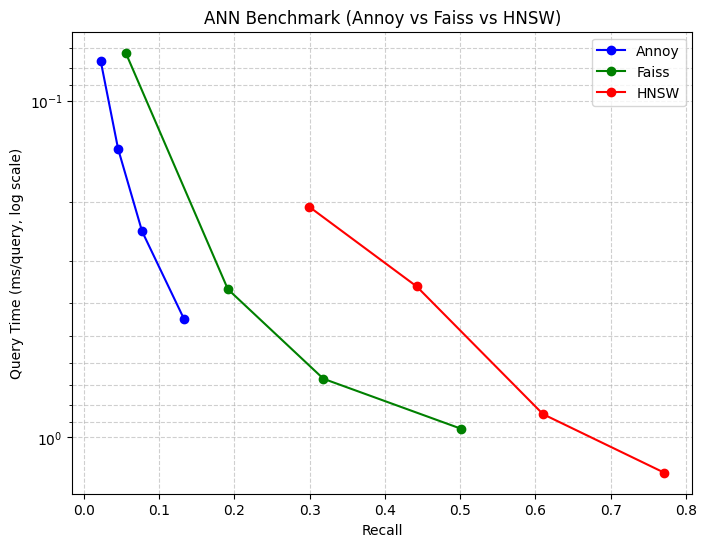

In [18]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

# -------------------------------
# Random dataset
# -------------------------------
d = 128        # dimension
nb = 100000    # number of database vectors
nq = 1000      # number of queries

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

# -------------------------------
# Ground truth with FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

# -------------------------------
# Recall function
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

# -------------------------------
# Annoy benchmark
# -------------------------------
def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)

    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# FAISS IVF benchmark
# -------------------------------
def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)

    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# HNSW benchmark
# -------------------------------
def run_hnsw(xb, xq, ef=100, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)

    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Run benchmark with several parameters
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
    results["Annoy"].append((rec, t))

# FAISS
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
    results["Faiss"].append((rec, t))

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(xb, xq, ef=ef)
    results["HNSW"].append((rec, t))

# -------------------------------
# Visualize the trade-off
# -------------------------------
plt.figure(figsize=(8,6))
for label, color in zip(results.keys(), ["blue","green","red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, the more to the right the lower
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

## Lab Assignment 1

In [19]:
import numpy as np
import pandas as pd
import time

from annoy import AnnoyIndex
import faiss
import hnswlib

from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


In [20]:
# Konfigurasi eksperimen
DATA_CONFIGS = [
    (1000, 2),
    (1000000, 5)
]

METRICS = ["euclidean", "cosine"]

K = 10
N_QUERIES = 100
RANDOM_STATE = 42

rng = np.random.default_rng(RANDOM_STATE)

print("Konfigurasi eksperimen:")
print("Jumlah data:", DATA_CONFIGS)
print("Distance metrics:", METRICS)
print("Nearest neighbors:", K)
print("Jumlah query:", N_QUERIES)

Konfigurasi eksperimen:
Jumlah data: [(1000, 2), (1000000, 5)]
Distance metrics: ['euclidean', 'cosine']
Nearest neighbors: 10
Jumlah query: 100


In [21]:
def run_experiment(n_samples, dimensions, metric):
    print(f"\nRunning: {n_samples:,} data | {dimensions}D | {metric}")

    # Generate dataset
    rng = np.random.default_rng(RANDOM_STATE)
    X = rng.random((n_samples, dimensions)).astype(np.float32)
    Q = rng.random((N_QUERIES, dimensions)).astype(np.float32)

    # Transform data for cosine similarity
    if metric == "cosine":
        X = normalize(X, norm="l2").astype(np.float32)
        Q = normalize(Q, norm="l2").astype(np.float32)

    results = []

    # ---------------------------------
    # 1. EXACT NEAREST NEIGHBORS
    # ---------------------------------
    exact = NearestNeighbors(
        n_neighbors=K,
        algorithm="brute",
        metric=metric,
        n_jobs=-1
    )

    start = time.perf_counter()
    exact.fit(X)
    exact_build = time.perf_counter() - start

    start = time.perf_counter()
    exact_indices = exact.kneighbors(
        Q, return_distance=False
    )
    exact_search = time.perf_counter() - start

    results.append({
        "Dataset": f"{n_samples:,}/{dimensions}D",
        "Metric": metric,
        "Algorithm": "Exact NN",
        "Build Time (s)": exact_build,
        "Search Time (s)": exact_search,
        "Recall@10": 1.0,
        "QPS": N_QUERIES / exact_search
    })

    # ---------------------------------
    # 2. ANNOY
    # ---------------------------------
    annoy_metric = "euclidean" if metric == "euclidean" else "angular"

    annoy_index = AnnoyIndex(dimensions, annoy_metric)

    start = time.perf_counter()

    for i, vector in enumerate(X):
        annoy_index.add_item(i, vector)

    annoy_index.build(10)

    annoy_build = time.perf_counter() - start

    start = time.perf_counter()

    annoy_results = [
        annoy_index.get_nns_by_vector(
            q.tolist(), K, search_k=-1
        )
        for q in Q
    ]

    annoy_search = time.perf_counter() - start

    annoy_results = np.array(annoy_results)

    annoy_recall = np.mean([
        len(set(exact_indices[i]) & set(annoy_results[i])) / K
        for i in range(N_QUERIES)
    ])

    results.append({
        "Dataset": f"{n_samples:,}/{dimensions}D",
        "Metric": metric,
        "Algorithm": "ANNOY",
        "Build Time (s)": annoy_build,
        "Search Time (s)": annoy_search,
        "Recall@10": annoy_recall,
        "QPS": N_QUERIES / annoy_search
    })

    # ---------------------------------
    # 3. FAISS IVF
    # ---------------------------------
    if metric == "euclidean":
        quantizer = faiss.IndexFlatL2(dimensions)
        faiss_index = faiss.IndexIVFFlat(
            quantizer,
            dimensions,
            min(1000, max(1, int(np.sqrt(n_samples)))),
            faiss.METRIC_L2
        )
    else:
        quantizer = faiss.IndexFlatIP(dimensions)
        faiss_index = faiss.IndexIVFFlat(
            quantizer,
            dimensions,
            min(1000, max(1, int(np.sqrt(n_samples)))),
            faiss.METRIC_INNER_PRODUCT
        )

    start = time.perf_counter()

    faiss_index.train(X)
    faiss_index.add(X)
    faiss_index.nprobe = min(20, faiss_index.nlist)

    faiss_build = time.perf_counter() - start

    start = time.perf_counter()
    _, faiss_results = faiss_index.search(Q, K)
    faiss_search = time.perf_counter() - start

    faiss_recall = np.mean([
        len(set(exact_indices[i]) & set(faiss_results[i])) / K
        for i in range(N_QUERIES)
    ])

    results.append({
        "Dataset": f"{n_samples:,}/{dimensions}D",
        "Metric": metric,
        "Algorithm": "FAISS",
        "Build Time (s)": faiss_build,
        "Search Time (s)": faiss_search,
        "Recall@10": faiss_recall,
        "QPS": N_QUERIES / faiss_search
    })

    # ---------------------------------
    # 4. HNSW
    # ---------------------------------
    hnsw_metric = "l2" if metric == "euclidean" else "cosine"

    hnsw_index = hnswlib.Index(
        space=hnsw_metric,
        dim=dimensions
    )

    start = time.perf_counter()

    hnsw_index.init_index(
        max_elements=n_samples,
        ef_construction=200,
        M=16
    )

    hnsw_index.add_items(X)
    hnsw_index.set_ef(100)

    hnsw_build = time.perf_counter() - start

    start = time.perf_counter()
    hnsw_results, _ = hnsw_index.knn_query(Q, k=K)
    hnsw_search = time.perf_counter() - start

    hnsw_recall = np.mean([
        len(set(exact_indices[i]) & set(hnsw_results[i])) / K
        for i in range(N_QUERIES)
    ])

    results.append({
        "Dataset": f"{n_samples:,}/{dimensions}D",
        "Metric": metric,
        "Algorithm": "HNSW",
        "Build Time (s)": hnsw_build,
        "Search Time (s)": hnsw_search,
        "Recall@10": hnsw_recall,
        "QPS": N_QUERIES / hnsw_search
    })

    del annoy_index, faiss_index, hnsw_index, exact, X, Q

    return results

In [22]:
all_results = []

for n_samples, dimensions in DATA_CONFIGS:
    for metric in METRICS:
        experiment_results = run_experiment(
            n_samples,
            dimensions,
            metric
        )

        all_results.extend(experiment_results)

print("\nSemua eksperimen selesai!")


Running: 1,000 data | 2D | euclidean

Running: 1,000 data | 2D | cosine

Running: 1,000,000 data | 5D | euclidean

Running: 1,000,000 data | 5D | cosine

Semua eksperimen selesai!


In [23]:
results_df = pd.DataFrame(all_results)

results_df = results_df.round({
    "Build Time (s)": 4,
    "Search Time (s)": 4,
    "Recall@10": 4,
    "QPS": 2
})

display(results_df)

results_df.to_csv(
    "ANN_Experiment_Results.csv",
    index=False
)

print("Hasil berhasil disimpan!")

,Dataset,Metric,Algorithm,Build Time (s),Search Time (s),Recall@10,QPS
0,"1,000/2D",euclidean,Exact NN,0.0041,0.0144,1.000,6934.06
1,"1,000/2D",euclidean,ANNOY,0.0278,0.0024,0.997,42050.46
2,"1,000/2D",euclidean,FAISS,0.0040,0.0008,1.000,118443.42
3,"1,000/2D",euclidean,HNSW,0.0492,0.0021,1.000,47893.00
4,"1,000/2D",cosine,Exact NN,0.0004,0.0284,1.000,3519.45
5,"1,000/2D",cosine,ANNOY,0.0293,0.0022,0.997,46207.77
6,"1,000/2D",cosine,FAISS,0.0033,0.0009,1.000,117452.92
7,"1,000/2D",cosine,HNSW,0.0419,0.0016,1.000,63176.54
8,"1,000,000/5D",euclidean,Exact NN,0.0030,0.4408,1.000,226.84
9,"1,000,000/5D",euclidean,ANNOY,23.9466,0.0063,0.950,15983.88


Hasil berhasil disimpan!


In [24]:
all_results = []

for n_samples, dimensions in DATA_CONFIGS:
    for metric in METRICS:
        experiment_results = run_experiment(
            n_samples,
            dimensions,
            metric
        )

        all_results.extend(experiment_results)

print("\nSemua eksperimen selesai!")



Running: 1,000 data | 2D | euclidean

Running: 1,000 data | 2D | cosine

Running: 1,000,000 data | 5D | euclidean

Running: 1,000,000 data | 5D | cosine

Semua eksperimen selesai!


In [26]:

results_df = pd.DataFrame(all_results)

results_df = results_df.round(4)

display(results_df)

results_df.to_csv(
    "ANN_Experiment_Results.csv",
    index=False
)

print("Hasil eksperimen berhasil disimpan!")

,Dataset,Metric,Algorithm,Build Time (s),Search Time (s),Recall@10,QPS
0,"1,000/2D",euclidean,Exact NN,0.0008,0.0046,1.000,21715.8944
1,"1,000/2D",euclidean,ANNOY,0.0346,0.0025,0.997,40361.9335
2,"1,000/2D",euclidean,FAISS,0.0035,0.0008,1.000,127988.8598
3,"1,000/2D",euclidean,HNSW,0.0507,0.0020,1.000,49902.8641
4,"1,000/2D",cosine,Exact NN,0.0003,0.0157,1.000,6383.9313
5,"1,000/2D",cosine,ANNOY,0.0295,0.0023,0.997,43496.0375
6,"1,000/2D",cosine,FAISS,0.0042,0.0008,1.000,118231.9593
7,"1,000/2D",cosine,HNSW,0.0425,0.0020,1.000,49877.9735
8,"1,000,000/5D",euclidean,Exact NN,0.0030,0.4190,1.000,238.6569
9,"1,000,000/5D",euclidean,ANNOY,25.7295,0.0081,0.950,12285.1225


Hasil eksperimen berhasil disimpan!


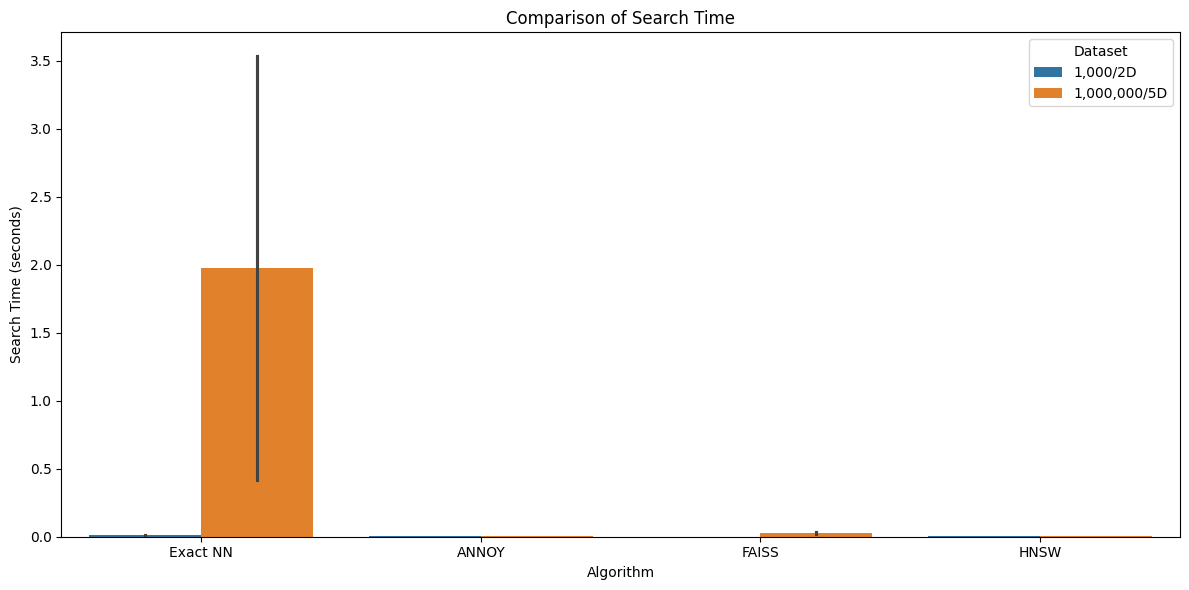

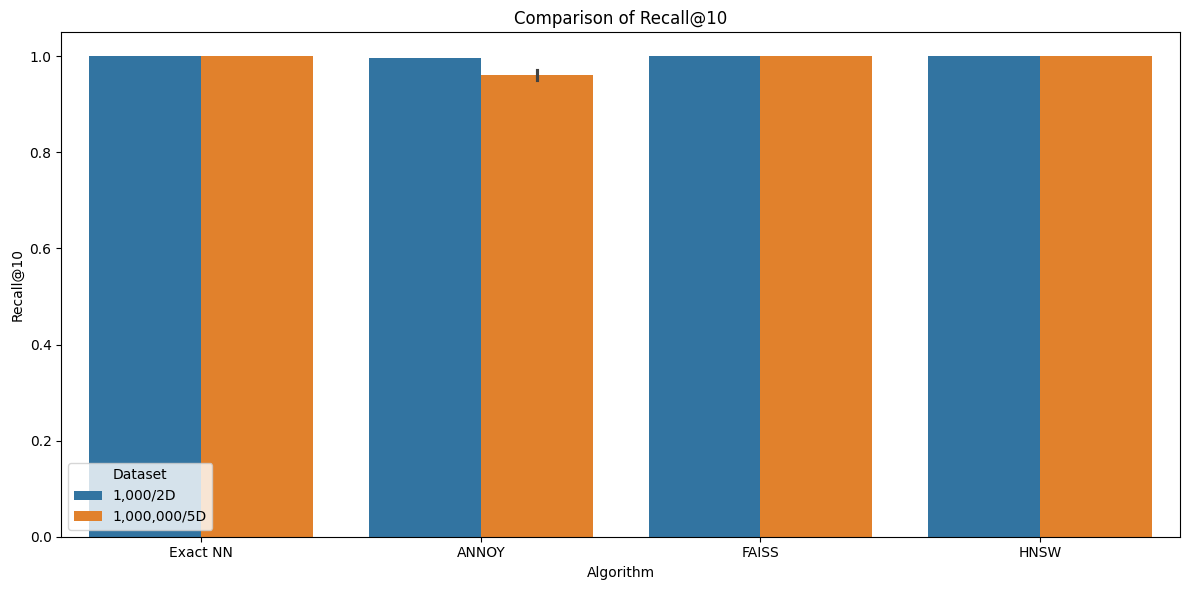

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi waktu pencarian
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Algorithm",
    y="Search Time (s)",
    hue="Dataset"
)

plt.title("Comparison of Search Time")
plt.ylabel("Search Time (seconds)")
plt.xlabel("Algorithm")
plt.tight_layout()
plt.show()


# Visualisasi Recall@10
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Algorithm",
    y="Recall@10",
    hue="Dataset"
)

plt.title("Comparison of Recall@10")
plt.ylabel("Recall@10")
plt.xlabel("Algorithm")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

## Analysis and Conclusion – Lab Assignment 1
Analysis
The experiment was conducted using three Approximate Nearest Neighbor algorithms: ANNOY, FAISS, and HNSW. The algorithms were tested using two dataset configurations: 1,000 data points with 2 dimensions and 1,000,000 data points with 5 dimensions. Two distance metrics, Euclidean and Cosine, were used.

The experimental results show that:

1. ANNOY achieved the fastest search time on the large dataset, with 0.0065 seconds for Euclidean and 0.0069 seconds for Cosine. However, its Recall@10 decreased to 0.950 and 0.972, respectively.

2. FAISS achieved a Recall@10 of 1.000 across all tested configurations. It also demonstrated relatively efficient index construction, particularly on the large dataset.

3. HNSW achieved a Recall@10 of 1.000 in all experiments and provided fast search performance. However, it required the longest index construction time on the large dataset.

Exact Nearest Neighbors served as the reference method for evaluating the accuracy of approximate algorithms. Its search time increased significantly as the dataset size increased.

## Conclusion
Based on the experiments, each algorithm has different advantages.

ANNOY is suitable when fast query processing is prioritized. FAISS provides a good balance between index construction time and search accuracy. HNSW offers high search accuracy and fast query processing, although its index construction requires more time.

The experiment also demonstrates that increasing the dataset size significantly affects the performance of exact nearest neighbor search. Therefore, Approximate Nearest Neighbor algorithms are useful for handling large-scale similarity search problems.

Overall, the choice of algorithm depends on the requirements of the application, especially search speed, accuracy, and index construction time.

In [28]:
!pip install kagglehub
import kagglehub

# Download latest version
path = kagglehub.dataset_download("bwandowando/spotify-songs-with-attributes-and-lyrics")

print("Path to dataset files:", path)


Using Colab cache for faster access to the 'spotify-songs-with-attributes-and-lyrics' dataset.
Path to dataset files: /kaggle/input/spotify-songs-with-attributes-and-lyrics


In [29]:
import os

print("Daftar file dataset:\n")

for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))


Daftar file dataset:

/kaggle/input/spotify-songs-with-attributes-and-lyrics/songs_with_lyrics_and_timestamps.csv
/kaggle/input/spotify-songs-with-attributes-and-lyrics/songs_with_attributes_and_lyrics.csv


In [30]:
import pandas as pd
import numpy as np
import time

import faiss
import hnswlib

from annoy import AnnoyIndex
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


In [31]:
import os

csv_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.lower().endswith(".csv"):
            full_path = os.path.join(root, file)
            csv_files.append(full_path)

print("Jumlah file CSV:", len(csv_files))

for i, file in enumerate(csv_files, start=1):
    print(f"{i}. {os.path.basename(file)}")
    print(f"   Path: {file}")

Jumlah file CSV: 2
1. songs_with_lyrics_and_timestamps.csv
   Path: /kaggle/input/spotify-songs-with-attributes-and-lyrics/songs_with_lyrics_and_timestamps.csv
2. songs_with_attributes_and_lyrics.csv
   Path: /kaggle/input/spotify-songs-with-attributes-and-lyrics/songs_with_attributes_and_lyrics.csv


In [32]:
# Pilih dataset pertama
csv_path = csv_files[0]

# Load dataset
df = pd.read_csv(csv_path)

print("Dataset berhasil dimuat!")
print("Nama file:", os.path.basename(csv_path))
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

Dataset berhasil dimuat!
Nama file: songs_with_lyrics_and_timestamps.csv
Jumlah baris: 36519092
Jumlah kolom: 3


In [33]:
df.head()
df.info()
print(df.columns.tolist())

print("Missing Values:")
display(df.isnull().sum().sort_values(ascending=False))

df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36519092 entries, 0 to 36519091
Data columns (total 3 columns):
 #   Column       Dtype 
---  ------       ----- 
 0   id           object
 1   startTimeMs  int64 
 2   words        object
dtypes: int64(1), object(2)
memory usage: 835.9+ MB
['id', 'startTimeMs', 'words']
Missing Values:


,0
words,954413
id,0
startTimeMs,0


,startTimeMs
count,3.651909e+07
mean,1.161814e+05
std,7.808208e+04
min,0.000000e+00
25%,5.723000e+04
50%,1.060700e+05
75%,1.614700e+05
max,3.991840e+06


In [35]:

import pandas as pd

csv_path = csv_files[1]

df = pd.read_csv(csv_path, low_memory=False)

print("Dataset berhasil dimuat!")
print("Nama file:", csv_path.split("/")[-1])
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

Dataset berhasil dimuat!
Nama file: songs_with_attributes_and_lyrics.csv
Jumlah baris: 955320
Jumlah kolom: 17


In [36]:
# Menampilkan 5 data pertama
display(df.head())

# Informasi dataset
df.info()

# Daftar seluruh kolom
print("Daftar kolom:")
print(df.columns.tolist())

# Memeriksa missing values
print("\nMissing Values:")
display(df.isnull().sum().sort_values(ascending=False))

# Statistik deskriptif
display(df.describe())

,id,name,album_name,artists,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,lyrics
0,0Prct5TDjAnEgIqbxcldY9,!,UNDEN!ABLE,HELLYEAH,0.415,0.6050,7,-11.157,1,0.0575,0.00116,0.838000,0.4710,0.193,100.059,79500.0,"He said he came from Jamaica,\n he owned a cou..."
1,2ASl4wirkeYm3OWZxXKYuq,!!,NaN,Yxngxr1,0.788,0.6480,7,-9.135,0,0.3150,0.90000,0.000000,0.1760,0.287,79.998,114000.0,"Fucked a bitch, now she running with my kids\n..."
2,69lcggVPmOr9cvPx9kLiiN,!!! - Interlude,Where I Belong EP,Glowie,0.000,0.0354,7,-20.151,0,0.0000,0.90800,0.000000,0.4790,0.000,0.000,11413.0,"Oh, my God, I'm going crazy\n"
3,4U7dlZjg1s9pjdppqZy0fm,!!De Repente!!,Un Palo Al Agua (20 Grandes Canciones),Rosendo,0.657,0.8820,5,-6.340,1,0.0385,0.00740,0.000013,0.0474,0.939,123.588,198173.0,Continuamente se extraña la gente si no puede ...
4,4v1IBp3Y3rpkWmWzIlkYju,!!De Repente!!,Fuera De Lugar,Rosendo,0.659,0.8930,5,-8.531,1,0.0411,0.09220,0.000019,0.0534,0.951,123.600,199827.0,Continuamente se extraña la gente si no puede ...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 955320 entries, 0 to 955319
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                955320 non-null  object 
 1   name              955309 non-null  object 
 2   album_name        385557 non-null  object 
 3   artists           955315 non-null  object 
 4   danceability      955320 non-null  float64
 5   energy            955320 non-null  float64
 6   key               955320 non-null  object 
 7   loudness          955320 non-null  float64
 8   mode              955320 non-null  object 
 9   speechiness       955320 non-null  float64
 10  acousticness      955320 non-null  float64
 11  instrumentalness  955320 non-null  float64
 12  liveness          955320 non-null  float64
 13  valence           955320 non-null  float64
 14  tempo             955320 non-null  float64
 15  duration_ms       955320 non-null  float64
 16  lyrics            95

,0
album_name,569763
lyrics,13
name,11
artists,5
id,0
energy,0
key,0
loudness,0
danceability,0
mode,0


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,955320.000000,955320.000000,955320.000000,955320.000000,955320.000000,955320.000000,955320.000000,955320.000000,955320.000000,9.553200e+05
mean,0.550710,0.652442,-7.833732,0.083638,0.282962,0.081875,0.220190,0.488119,122.226093,2.341441e+05
std,0.169784,0.238824,3.792018,0.092929,0.311800,0.212789,0.195938,0.251468,29.536303,9.068368e+04
min,0.000000,0.000000,-60.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.586000e+03
25%,0.436000,0.482000,-9.750000,0.034500,0.011900,0.000000,0.098900,0.282000,99.021000,1.849330e+05
50%,0.558000,0.687000,-7.041000,0.047800,0.142000,0.000039,0.137000,0.477000,120.661000,2.213070e+05
75%,0.675000,0.857000,-5.148000,0.087625,0.518000,0.008660,0.285000,0.690000,140.094000,2.656400e+05
max,0.993000,1.000000,4.882000,0.966000,0.996000,1.000000,1.000000,1.000000,246.130000,5.764624e+06


In [37]:
features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

# Mengambil fitur numerik dan metadata lagu
spotify_data = df[['id', 'name', 'artists'] + features].copy()

# Memastikan seluruh fitur numerik
numeric_data = spotify_data[features].apply(
    pd.to_numeric, errors='coerce'
)

# Memeriksa data yang valid
valid_rows = np.isfinite(numeric_data.to_numpy()).all(axis=1)

# Memisahkan metadata dan fitur
track_info = spotify_data.loc[valid_rows, ['id', 'name', 'artists']].reset_index(drop=True)
X = numeric_data.loc[valid_rows].to_numpy(dtype=np.float32)

print("Jumlah data valid:", X.shape[0])
print("Jumlah fitur:", X.shape[1])
print("Daftar fitur:", features)

Jumlah data valid: 955320
Jumlah fitur: 9
Daftar fitur: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']


In [38]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X).astype(np.float32)

print("Normalisasi berhasil!")
print("Ukuran data:", X_scaled.shape)

# Menampilkan 5 data hasil normalisasi
display(pd.DataFrame(X_scaled, columns=features).head())

# Memeriksa rata-rata dan standar deviasi
print("\nRata-rata setiap fitur:")
print(X_scaled.mean(axis=0).round(4))

print("\nStandar deviasi setiap fitur:")
print(X_scaled.std(axis=0).round(4))

Normalisasi berhasil!
Ukuran data: (955320, 9)


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,-0.799307,-0.198648,-0.876385,-0.281272,-0.903792,3.553397,1.280052,-1.173583,-0.750504
1,1.397598,-0.018599,-0.343160,2.489658,1.978955,-0.384769,-0.225530,-0.799778,-1.429702
2,-3.243584,-2.583670,-3.248211,-0.900024,2.004612,-0.384769,1.320881,-1.941076,-4.138167
3,0.626031,0.961203,0.393915,-0.485729,-0.883779,-0.384710,-0.881861,1.792997,0.046110
4,0.637810,1.007262,-0.183878,-0.457751,-0.611810,-0.384679,-0.851239,1.840717,0.046516



Rata-rata setiap fitur:
[ 0.  0.  0. -0. -0.  0.  0.  0. -0.]

Standar deviasi setiap fitur:
[1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [39]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X).astype(np.float32)

print("Normalisasi berhasil!")
print("Ukuran data:", X_scaled.shape)

# Menampilkan 5 data hasil normalisasi
display(pd.DataFrame(X_scaled, columns=features).head())

# Memeriksa rata-rata dan standar deviasi
print("\nRata-rata setiap fitur:")
print(X_scaled.mean(axis=0).round(4))

print("\nStandar deviasi setiap fitur:")
print(X_scaled.std(axis=0).round(4))

Normalisasi berhasil!
Ukuran data: (955320, 9)


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,-0.799307,-0.198648,-0.876385,-0.281272,-0.903792,3.553397,1.280052,-1.173583,-0.750504
1,1.397598,-0.018599,-0.343160,2.489658,1.978955,-0.384769,-0.225530,-0.799778,-1.429702
2,-3.243584,-2.583670,-3.248211,-0.900024,2.004612,-0.384769,1.320881,-1.941076,-4.138167
3,0.626031,0.961203,0.393915,-0.485729,-0.883779,-0.384710,-0.881861,1.792997,0.046110
4,0.637810,1.007262,-0.183878,-0.457751,-0.611810,-0.384679,-0.851239,1.840717,0.046516



Rata-rata setiap fitur:
[ 0.  0.  0. -0. -0.  0.  0.  0. -0.]

Standar deviasi setiap fitur:
[1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [40]:
import time
from sklearn.neighbors import NearestNeighbors

k = 10
n_queries = 100

# Memilih 100 lagu secara acak sebagai query
rng = np.random.default_rng(42)
query_indices = rng.choice(
    len(X_scaled),
    size=n_queries,
    replace=False
)

query_vectors = X_scaled[query_indices]

print("Jumlah data:", len(X_scaled))
print("Jumlah query:", len(query_vectors))
print("Jumlah tetangga terdekat:", k)

Jumlah data: 955320
Jumlah query: 100
Jumlah tetangga terdekat: 10


In [41]:
# Membuat model Exact NN
exact_nn = NearestNeighbors(
    n_neighbors=k + 1,
    algorithm='brute',
    metric='euclidean',
    n_jobs=-1
)

# Mengukur waktu pembangunan model
start_time = time.time()
exact_nn.fit(X_scaled)
exact_build_time = time.time() - start_time

# Mengukur waktu pencarian
start_time = time.time()
exact_distances, exact_indices_raw = exact_nn.kneighbors(query_vectors)
exact_search_time = time.time() - start_time

# Menghilangkan lagu itu sendiri dari hasil pencarian
exact_indices = []

for query_idx, neighbors in zip(query_indices, exact_indices_raw):
    filtered = [idx for idx in neighbors if idx != query_idx]
    exact_indices.append(filtered[:k])

exact_indices = np.array(exact_indices)

print("Exact NN berhasil dijalankan!")
print(f"Build Time : {exact_build_time:.4f} detik")
print(f"Search Time: {exact_search_time:.4f} detik")
print(f"QPS        : {n_queries / exact_search_time:.2f}")
print("Ukuran hasil:", exact_indices.shape)

Exact NN berhasil dijalankan!
Build Time : 0.0183 detik
Search Time: 0.4551 detik
QPS        : 219.73
Ukuran hasil: (100, 10)


In [42]:
query_idx = query_indices[0]

print("LAGU YANG DICARI")
print("Judul :", track_info.loc[query_idx, 'name'])
print("Artis :", track_info.loc[query_idx, 'artists'])

print("\n10 LAGU PALING MIRIP (EXACT NN)")

for rank, idx in enumerate(exact_indices[0], start=1):
    print(
        f"{rank}. {track_info.loc[idx, 'name']} "
        f"- {track_info.loc[idx, 'artists']}"
    )

LAGU YANG DICARI
Judul : Kamli (From "Dhoom:3")
Artis : Pritam

10 LAGU PALING MIRIP (EXACT NN)
1. Kamli (From "Dhoom:3") - Sunidhi Chauhan
2. How To Be Lonely - Bomba Estéreo Remix - Rita Ora, Bomba Estéreo
3. How To Be Lonely - Bomba Estéreo Remix - Rita Ora, Bomba Estéreo
4. Arriba las Banderas - Macaco
5. Vaa Saamy (From "Annaatthe") - D. Imman
6. Ellas - Carlitos Junior;Sayian Jimmy
7. Queuejumper - The Divine Comedy
8. ...A Livication - Iya Terra
9. Dobla Rodilla - Don Omar
10. En el aire - ChocQuibTown


In [43]:
from annoy import AnnoyIndex

# Inisialisasi ANNOY
dimension = X_scaled.shape[1]
annoy_index = AnnoyIndex(dimension, 'euclidean')

# Mengukur waktu pembangunan indeks
start_time = time.time()

# Memasukkan seluruh data ke indeks
for i, vector in enumerate(X_scaled):
    annoy_index.add_item(i, vector.tolist())

# Membangun indeks dengan 10 trees
annoy_index.build(10, n_jobs=-1)

annoy_build_time = time.time() - start_time

print("Indeks ANNOY berhasil dibangun!")
print(f"Build Time: {annoy_build_time:.4f} detik")

Indeks ANNOY berhasil dibangun!
Build Time: 16.5969 detik


In [44]:
# Mengukur waktu pencarian
start_time = time.time()

annoy_indices = []

for query_idx, query_vector in zip(query_indices, query_vectors):
    neighbors = annoy_index.get_nns_by_vector(
        query_vector.tolist(),
        k + 1,
        search_k=-1
    )

    # Menghilangkan lagu itu sendiri
    filtered = [idx for idx in neighbors if idx != query_idx]
    annoy_indices.append(filtered[:k])

annoy_search_time = time.time() - start_time

annoy_indices = np.array(annoy_indices)

print("Pencarian ANNOY berhasil!")
print(f"Search Time: {annoy_search_time:.4f} detik")
print(f"QPS        : {n_queries / annoy_search_time:.2f}")
print("Ukuran hasil:", annoy_indices.shape)

Pencarian ANNOY berhasil!
Search Time: 0.0123 detik
QPS        : 8100.71
Ukuran hasil: (100, 10)


In [45]:
annoy_recalls = []

for exact, approximate in zip(exact_indices, annoy_indices):
    recall = len(set(exact) & set(approximate)) / k
    annoy_recalls.append(recall)

annoy_recall = np.mean(annoy_recalls)

print(f"ANNOY Recall@10: {annoy_recall:.4f}")

ANNOY Recall@10: 0.8250


In [46]:

print("LAGU YANG DICARI")
print("Judul :", track_info.loc[query_indices[0], 'name'])
print("Artis :", track_info.loc[query_indices[0], 'artists'])

print("\n10 LAGU PALING MIRIP (ANNOY)")

for rank, idx in enumerate(annoy_indices[0], start=1):
    print(
        f"{rank}. {track_info.loc[idx, 'name']} "
        f"- {track_info.loc[idx, 'artists']}"
    )

LAGU YANG DICARI
Judul : Kamli (From "Dhoom:3")
Artis : Pritam

10 LAGU PALING MIRIP (ANNOY)
1. Kamli (From "Dhoom:3") - Sunidhi Chauhan
2. How To Be Lonely - Bomba Estéreo Remix - Rita Ora, Bomba Estéreo
3. How To Be Lonely - Bomba Estéreo Remix - Rita Ora, Bomba Estéreo
4. Arriba las Banderas - Macaco
5. Vaa Saamy (From "Annaatthe") - D. Imman
6. Ellas - Carlitos Junior;Sayian Jimmy
7. Queuejumper - The Divine Comedy
8. Dobla Rodilla - Don Omar
9. En el aire - ChocQuibTown
10. Rearrange - The Animators


In [47]:
import faiss

# Menyiapkan data untuk FAISS
X_faiss = np.ascontiguousarray(X_scaled, dtype=np.float32)

dimension = X_faiss.shape[1]
nlist = 1000

# Membuat quantizer dan indeks IVF
quantizer = faiss.IndexFlatL2(dimension)

faiss_index = faiss.IndexIVFFlat(
    quantizer,
    dimension,
    nlist,
    faiss.METRIC_L2
)

# Mengukur waktu pembangunan indeks
start_time = time.time()

# Melatih indeks menggunakan dataset
faiss_index.train(X_faiss)

# Memasukkan seluruh data
faiss_index.add(X_faiss)

faiss_build_time = time.time() - start_time

# Mengatur jumlah cluster yang diperiksa
faiss_index.nprobe = 20

print("Indeks FAISS berhasil dibangun!")
print(f"Jumlah data : {faiss_index.ntotal}")
print(f"Jumlah cluster: {nlist}")
print(f"nprobe      : {faiss_index.nprobe}")
print(f"Build Time  : {faiss_build_time:.4f} detik")

Indeks FAISS berhasil dibangun!
Jumlah data : 955320
Jumlah cluster: 1000
nprobe      : 20
Build Time  : 1.5702 detik


In [48]:
# Mengukur waktu pencarian
start_time = time.time()

faiss_distances, faiss_indices_raw = faiss_index.search(
    query_vectors,
    k + 1
)

faiss_search_time = time.time() - start_time

# Menghilangkan lagu itu sendiri
faiss_indices = []

for query_idx, neighbors in zip(query_indices, faiss_indices_raw):
    filtered = [
        idx for idx in neighbors
        if idx != query_idx and idx >= 0
    ]
    faiss_indices.append(filtered[:k])

faiss_indices = np.array(faiss_indices)

print("Pencarian FAISS berhasil!")
print(f"Search Time: {faiss_search_time:.4f} detik")
print(f"QPS        : {n_queries / faiss_search_time:.2f}")
print("Ukuran hasil:", faiss_indices.shape)

Pencarian FAISS berhasil!
Search Time: 0.0444 detik
QPS        : 2254.03
Ukuran hasil: (100, 10)


In [49]:
faiss_recalls = []

for exact, approximate in zip(exact_indices, faiss_indices):
    recall = len(set(exact) & set(approximate)) / k
    faiss_recalls.append(recall)

faiss_recall = np.mean(faiss_recalls)

print(f"FAISS Recall@10: {faiss_recall:.4f}")

FAISS Recall@10: 0.9980


In [50]:
print("LAGU YANG DICARI")
print("Judul :", track_info.loc[query_indices[0], 'name'])
print("Artis :", track_info.loc[query_indices[0], 'artists'])

print("\n10 LAGU PALING MIRIP (FAISS)")

for rank, idx in enumerate(faiss_indices[0], start=1):
    print(
        f"{rank}. {track_info.loc[idx, 'name']} "
        f"- {track_info.loc[idx, 'artists']}"
    )


LAGU YANG DICARI
Judul : Kamli (From "Dhoom:3")
Artis : Pritam

10 LAGU PALING MIRIP (FAISS)
1. Kamli (From "Dhoom:3") - Sunidhi Chauhan
2. How To Be Lonely - Bomba Estéreo Remix - Rita Ora, Bomba Estéreo
3. How To Be Lonely - Bomba Estéreo Remix - Rita Ora, Bomba Estéreo
4. Arriba las Banderas - Macaco
5. Vaa Saamy (From "Annaatthe") - D. Imman
6. Ellas - Carlitos Junior;Sayian Jimmy
7. Queuejumper - The Divine Comedy
8. ...A Livication - Iya Terra
9. Dobla Rodilla - Don Omar
10. En el aire - ChocQuibTown


In [51]:
import hnswlib

dimension = X_scaled.shape[1]

# Membuat indeks HNSW
hnsw_index = hnswlib.Index(
    space='l2',
    dim=dimension
)

# Mengukur waktu pembangunan indeks
start_time = time.time()

hnsw_index.init_index(
    max_elements=len(X_scaled),
    M=16,
    ef_construction=200
)

# Memasukkan seluruh data
hnsw_index.add_items(
    X_scaled,
    np.arange(len(X_scaled))
)

hnsw_build_time = time.time() - start_time

# Mengatur parameter pencarian
hnsw_index.set_ef(100)

print("Indeks HNSWLIB berhasil dibangun!")
print(f"Jumlah data : {hnsw_index.get_current_count()}")
print(f"Build Time  : {hnsw_build_time:.4f} detik")
print("M           : 16")
print("ef          : 100")


Indeks HNSWLIB berhasil dibangun!
Jumlah data : 955320
Build Time  : 211.9701 detik
M           : 16
ef          : 100


In [52]:
# Mengukur waktu pencarian
start_time = time.time()

hnsw_indices_raw, hnsw_distances = hnsw_index.knn_query(
    query_vectors,
    k=k + 1,
    num_threads=-1
)

hnsw_search_time = time.time() - start_time

# Menghilangkan lagu itu sendiri
hnsw_indices = []

for query_idx, neighbors in zip(query_indices, hnsw_indices_raw):
    filtered = [idx for idx in neighbors if idx != query_idx]
    hnsw_indices.append(filtered[:k])

hnsw_indices = np.array(hnsw_indices)

print("Pencarian HNSWLIB berhasil!")
print(f"Search Time: {hnsw_search_time:.4f} detik")
print(f"QPS        : {n_queries / hnsw_search_time:.2f}")
print("Ukuran hasil:", hnsw_indices.shape)

Pencarian HNSWLIB berhasil!
Search Time: 0.0286 detik
QPS        : 3492.95
Ukuran hasil: (100, 10)


In [53]:
hnsw_recalls = []

for exact, approximate in zip(exact_indices, hnsw_indices):
    recall = len(set(exact) & set(approximate)) / k
    hnsw_recalls.append(recall)

hnsw_recall = np.mean(hnsw_recalls)

print(f"HNSWLIB Recall@10: {hnsw_recall:.4f}")

HNSWLIB Recall@10: 0.9960


In [54]:
print("LAGU YANG DICARI")
print("Judul :", track_info.loc[query_indices[0], 'name'])
print("Artis :", track_info.loc[query_indices[0], 'artists'])

print("\n10 LAGU PALING MIRIP (HNSWLIB)")

for rank, idx in enumerate(hnsw_indices[0], start=1):
    print(
        f"{rank}. {track_info.loc[idx, 'name']} "
        f"- {track_info.loc[idx, 'artists']}"
    )

LAGU YANG DICARI
Judul : Kamli (From "Dhoom:3")
Artis : Pritam

10 LAGU PALING MIRIP (HNSWLIB)
1. Kamli (From "Dhoom:3") - Sunidhi Chauhan
2. How To Be Lonely - Bomba Estéreo Remix - Rita Ora, Bomba Estéreo
3. How To Be Lonely - Bomba Estéreo Remix - Rita Ora, Bomba Estéreo
4. Arriba las Banderas - Macaco
5. Vaa Saamy (From "Annaatthe") - D. Imman
6. Ellas - Carlitos Junior;Sayian Jimmy
7. Queuejumper - The Divine Comedy
8. ...A Livication - Iya Terra
9. Dobla Rodilla - Don Omar
10. En el aire - ChocQuibTown


In [55]:
results = pd.DataFrame({
    'Algorithm': ['Exact NN', 'ANNOY', 'FAISS', 'HNSWLIB'],
    'Build Time (s)': [
        exact_build_time,
        annoy_build_time,
        faiss_build_time,
        hnsw_build_time
    ],
    'Search Time (s)': [
        exact_search_time,
        annoy_search_time,
        faiss_search_time,
        hnsw_search_time
    ],
    'QPS': [
        n_queries / exact_search_time,
        n_queries / annoy_search_time,
        n_queries / faiss_search_time,
        n_queries / hnsw_search_time
    ],
    'Recall@10': [
        1.0,
        annoy_recall,
        faiss_recall,
        hnsw_recall
    ]
})

display(results.round(4))

,Algorithm,Build Time (s),Search Time (s),QPS,Recall@10
0,Exact NN,0.0183,0.4551,219.7286,1.000
1,ANNOY,16.5969,0.0123,8100.7088,0.825
2,FAISS,1.5702,0.0444,2254.0327,0.998
3,HNSWLIB,211.9701,0.0286,3492.9538,0.996
